(np.float64(-0.5), np.float64(832.5), np.float64(461.5), np.float64(-0.5))

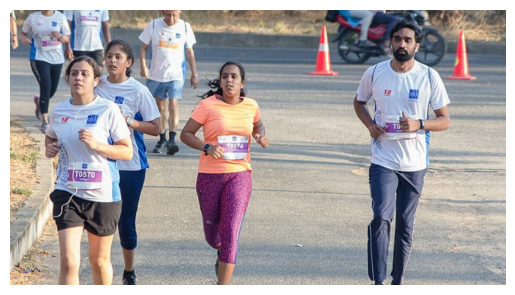

In [16]:
import torch, torchvision
from PIL import Image
from torchvision.transforms.functional import to_tensor
import matplotlib.pyplot as plt

img = Image.open("sample.jpg.png").convert("RGB")
x = to_tensor(img).unsqueeze(0)
plt.imshow(img)
plt.axis("off")

In [17]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn

model = fasterrcnn_resnet50_fpn(weights="DEFAULT").eval()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\Lenovo/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|███████████████████████████████████████████████████████████████████████████████| 160M/160M [00:13<00:00, 12.7MB/s]


In [18]:
with torch.no_grad():
    output = model(x)

for box, score, label in zip(output[0]["boxes"], output[0]["scores"], output[0]["labels"]):
    if score > 0.5:
        print("Label:", label.item(), "Box:", box.tolist(), "Confidence:", round(score.item(), 2))

Label: 1 Box: [579.0205078125, 18.001373291015625, 741.5613403320312, 458.11749267578125] Confidence: 1.0
Label: 1 Box: [284.6301574707031, 87.41374969482422, 436.73394775390625, 457.0521240234375] Confidence: 1.0
Label: 1 Box: [12.31592845916748, 1.8539390563964844, 106.7618408203125, 206.54759216308594] Confidence: 1.0
Label: 1 Box: [54.83259582519531, 68.06807708740234, 207.28659057617188, 462.0] Confidence: 1.0
Label: 1 Box: [212.2110137939453, 0.0, 317.6700439453125, 245.61569213867188] Confidence: 1.0
Label: 1 Box: [143.66944885253906, 51.08623123168945, 254.2125244140625, 460.526611328125] Confidence: 1.0
Label: 1 Box: [108.90325164794922, 0.0, 169.72265625, 95.40966796875] Confidence: 0.96
Label: 4 Box: [528.302001953125, 0.0, 733.9241333007812, 93.854248046875] Confidence: 0.93
Label: 1 Box: [0.32191213965415955, 2.2666006088256836, 14.26667594909668, 67.21540832519531] Confidence: 0.77
Label: 4 Box: [543.294189453125, 4.0295491218566895, 652.377197265625, 91.69225311279297] C

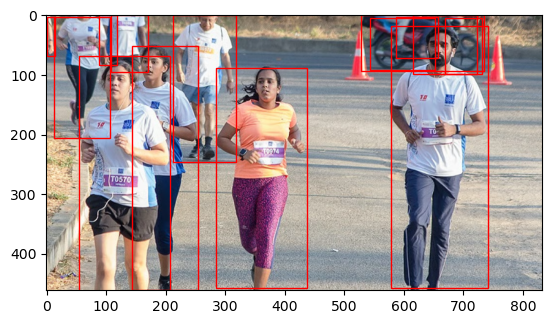

In [19]:
import matplotlib.patches as patches

fig, ax = plt.subplots()
ax.imshow(img)

for box, score in zip(output[0]["boxes"], output[0]["scores"]):
    if score > 0.5:
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(patches.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, edgecolor='red'))

plt.show()

In [20]:
import time

start = time.time()
with torch.no_grad():
    model(x)
print("FPS:", round(1/(time.time()-start), 2))

FPS: 0.23


In [21]:
from torchvision.models.detection import ssdlite320_mobilenet_v3_large

ssd = ssdlite320_mobilenet_v3_large(weights="DEFAULT").eval()

Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to C:\Users\Lenovo/.cache\torch\hub\checkpoints\ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|█████████████████████████████████████████████████████████████████████████████| 13.4M/13.4M [00:01<00:00, 11.1MB/s]


In [22]:
with torch.no_grad():
    result = ssd(x)

for box, score, label in zip(result[0]["boxes"], result[0]["scores"], result[0]["labels"]):
    if score > 0.5:
        print("Label:", label.item(), "Box:", box.tolist(), "Confidence:", round(score.item(), 2))

Label: 1 Box: [14.917112350463867, 0.0, 104.01895141601562, 184.1433868408203] Confidence: 0.99
Label: 1 Box: [280.89678955078125, 97.95936584472656, 430.1821594238281, 455.6702880859375] Confidence: 0.98
Label: 1 Box: [50.08514404296875, 72.90811920166016, 217.13768005371094, 462.0] Confidence: 0.94
Label: 1 Box: [218.52247619628906, 0.0, 309.7554626464844, 217.07667541503906] Confidence: 0.93
Label: 1 Box: [135.83201599121094, 59.434207916259766, 266.5518493652344, 451.1598205566406] Confidence: 0.71
Label: 1 Box: [548.5296630859375, 33.82863998413086, 742.615234375, 457.89398193359375] Confidence: 0.54


In [23]:
start = time.time()
with torch.no_grad():
    ssd(x)
print("SSD FPS:", round(1/(time.time()-start), 2))

SSD FPS: 3.44


In [24]:
print("Faster R-CNN: High accuracy, slower speed")
print("SSD MobileNet: Good accuracy, faster speed and low cost")

Faster R-CNN: High accuracy, slower speed
SSD MobileNet: Good accuracy, faster speed and low cost


In [26]:
import time

start = time.time()
with torch.no_grad():
    model(x)
fps1 = 1 / (time.time() - start)

start = time.time()
with torch.no_grad():
    ssd(x)
fps2 = 1 / (time.time() - start)

print("Faster R-CNN FPS:", round(fps1, 2))
print("SSD MobileNet FPS:", round(fps2, 2))

Faster R-CNN FPS: 0.19
SSD MobileNet FPS: 5.5


In [27]:
import pandas as pd

df = pd.DataFrame({
    "Model": ["Faster R-CNN", "SSD MobileNet"],
    "FPS": [round(fps1,2), round(fps2,2)],
    "Accuracy": ["High", "Good"],
    "Cost": ["High", "Low"]
})
print(df)

           Model   FPS Accuracy  Cost
0   Faster R-CNN  0.19     High  High
1  SSD MobileNet  5.50     Good   Low
